In [1]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\mrmik\Downloads\titanic")
df = pd.read_csv(BASE_DIR / "train.csv")

df_age = df.dropna(subset=['Age']).copy()

bins = [0, 25, 50, 100]
labels = ['0-25 лет', '25-50 лет', '50+ лет']
df_age['AgeGroup'] = pd.cut(df_age['Age'], bins=bins, labels=labels, right=False)

probabilities = df_age.groupby('AgeGroup', observed=True)['Survived'].mean()

probabilities_formatted = probabilities.apply("{:.2%}".format)

display(probabilities_formatted)

AgeGroup
0-25 лет     42.45%
25-50 лет    40.06%
50+ лет      36.49%
Name: Survived, dtype: str

In [2]:
import numpy as np

# Теорема Байеса
p_female = (df['Sex'] == 'female').mean()
p_survived_given_female = df[df['Sex'] == 'female']['Survived'].mean()
p_survived = df['Survived'].mean()
p_female_given_survived = (p_survived_given_female * p_female) / p_survived

# Проверка через условную вероятность на подвыборке
check = (df[df['Survived'] == 1]['Sex'] == 'female').mean()
display(pd.Series({
    'Байес': p_female_given_survived, 
    'Проверка (доля на подвыборке)': check
}).apply("{:.4%}".format))

# Вычисляем априорные вероятности классов
p_survived_0 = (df['Survived'] == 0).mean()
p_survived_1 = (df['Survived'] == 1).mean()

# Вычисляем условные вероятности для признаков
likelihoods = {}
for target in [0, 1]:
    subset = df[df['Survived'] == target]
    p_sex = subset['Sex'].value_counts(normalize=True)
    p_class = subset['Pclass'].value_counts(normalize=True)
    likelihoods[target] = {'sex': p_sex, 'class': p_class}

# Функция предсказания для одной строки
def predict_naive_bayes(row):
    # P(X | Survived=0) = P(Sex|0) * P(Pclass|0)
    prob_x_given_0 = likelihoods[0]['sex'].get(row['Sex'], 0) * likelihoods[0]['class'].get(row['Pclass'], 0)
    # P(X | Survived=1) = P(Sex|1) * P(Pclass|1)
    prob_x_given_1 = likelihoods[1]['sex'].get(row['Sex'], 0) * likelihoods[1]['class'].get(row['Pclass'], 0)
    score_0 = prob_x_given_0 * p_survived_0
    score_1 = prob_x_given_1 * p_survived_1
    return 1 if score_1 > score_0 else 0

# Применяем модель к датафрейму
df['NB_Prediction'] = df.apply(predict_naive_bayes, axis=1)

# Оцениваем точность
accuracy = (df['NB_Prediction'] == df['Survived']).mean()
print(f"Точность Наивного Байеса (Sex + Pclass): {accuracy:.2%}")

Байес                            68.1287%
Проверка (доля на подвыборке)    68.1287%
dtype: str

Точность Наивного Байеса (Sex + Pclass): 78.68%


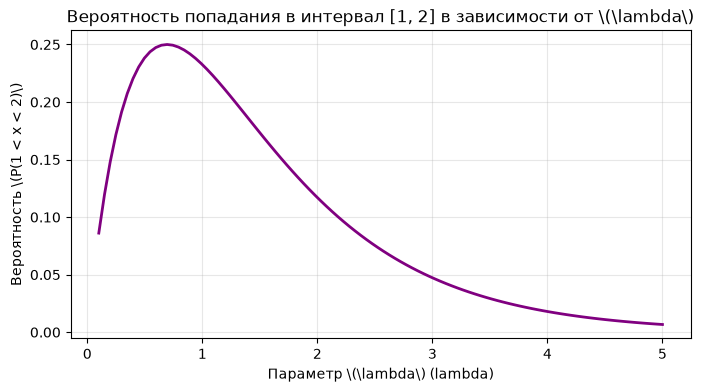

Площадь под всей кривой плотности (для lambda = 2.5): 1.0000


In [6]:
import matplotlib.pyplot as plt
from scipy.integrate import quad
import numpy as np

# Создаем массив значений лямбда
lambdas = np.linspace(0.1, 5.0, 100)
probs = []

# Вычисляем вероятность для каждой лямбды
for lam in lambdas:
    
    integral, _ = quad(lambda x: lam * np.exp(-lam * x), 1, 2)
    probs.append(integral)


plt.figure(figsize=(8, 4))
plt.plot(lambdas, probs, color='purple', linewidth=2)


plt.title(r'Вероятность попадания в интервал [1, 2] в зависимости от \(\lambda\)')
plt.xlabel(r'Параметр \(\lambda\) (lambda)')
plt.ylabel(r'Вероятность \(P(1 < x < 2)\)')
plt.grid(True, alpha=0.3)
plt.show()

# Конечна ли площадь под кривой для всех лямбд?
test_lambda = 2.5
# Интегрируем от 0 до бесконечности
total_area, _ = quad(lambda x: test_lambda * np.exp(-test_lambda * x), 0, np.inf)
print(f"Площадь под всей кривой плотности (для lambda = {test_lambda}): {total_area:.4f}")